# Разведочный анализ данных (Reddit C-SSRS)


В исследовании Gaur et al. (2021) изучались сообщения пользователей Reddit и экспертная оценка суицидального риска. В этом ноутбуке используется не весь корпус статьи, а подготовленная таблица из пяти Excel-файлов архива Suicide Risk Assessment Annotations.

По исходным пяти файлам было 4 272 строки. У 15 строк отсутствовал текст, поэтому в подготовленном CSV осталось 4 257 сообщений от 376 пользователей.

Метка относится к содержанию сообщения, а не является медицинским диагнозом автора. Неизвестную метку нельзя считать «отсутствием риска».

Источник: [Gaur et al., 2021 (PLOS ONE)](https://pmc.ncbi.nlm.nih.gov/articles/PMC8128252/).


## 1. Загрузка и таблица

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем CSV (сделала специально с компьютера или через окно Google Colab для удобства)
try:
    df = pd.read_csv("Reddit_C_SSRS.csv")
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))

# Первые 5 строк и размер данных
print("Размер таблицы:", df.shape)
print("Пользователей:", df["user_id"].nunique())
print("Столбцы:", df.columns.tolist())
display(df.head(20))

Размер таблицы: (4257, 7)
Пользователей: 376
Столбцы: ['user_id', 'post_index', 'text', 'original_label', 'label', 'annotation_status', 'source_file']


,user_id,post_index,text,original_label,label,annotation_status,source_file
0,user-655,0,Thank you very much for the picture. I printed...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
1,user-655,1,My girlfriend of 7 years recently broke up wit...,ideation,ideation,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
2,user-655,2,'I know how you feel man. My ex and I were tog...,indicator,indicator,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
3,user-655,3,'Try 7 years and a kid bub. It sucks when thin...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
4,user-655,4,'now youre putting the pussy on a pedestal hah...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
5,user-655,5,'Thats good to know. Im only familiar with vic...,indicator,indicator,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
6,user-655,6,'I think one of the hardest things about this ...,indicator,indicator,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
7,user-655,7,'Dont use that book as your basis of your unde...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
8,user-655,8,'Thank you. I actually am not on any medicati...,ideation,ideation,labeled,Redditors_and_posts_batch_I_anonymized.xlsx
9,user-655,9,'My girlfriend of 7 years recently broke up wi...,ideation,ideation,labeled,Redditors_and_posts_batch_I_anonymized.xlsx


Что означают столбцы:

user_id - пользователь,

post_index - номер сообщения в подготовленных данных,

text - текст,

original_label - исходная метка из Excel,

label — приведённая к одному написанию метка,

annotation_status — статус разметки,

source_file — исходный Excel-файл, откуда взяты значения.

ОГОВОРКА: Для унификации написания исходных меток использовалась ЛЛМ. Новая экспертная разметка при этом не выполнялась.

В таблице 4 257 сообщений от 376 пользователей. Одному пользователю может принадлежать несколько строк, поэтому число сообщений намного больше числа авторов.



In [12]:
!pip install ydata-profiling
%pip install "numpy==2.3.3"

In [13]:
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="EDA Report", explorative=True)
profile.to_notebook_iframe()
profile.to_file("EDA_Report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 7/7 [00:01<00:00,  5.32it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

#Краткий обзор датасета:

Датасет содержит 4257 текстовых записей от 376 пользователей Reddit. Из них 2680 записей имеют разметку, а оставшиеся 1577 являются неразмеченными.

Анализ показал отсутствие полных дубликатов строк, однако обнаружены 3 повторяющихся текста. Длина публикаций варьируется от 2 до 8048 символов, что говорит о значительных различиях в объёме сообщений.

В столбце original_label представлена исходная разметка, содержащая 21 уникальное значение. После унификации названий категорий в столбце label осталось 6 классов. Среди размеченных записей преобладает класс supportive (50,4%),что нам указывает на неравномерное распределение классов.

Пропущенные значения обнаружены в столбцах original_label и label (по 1577 записей). Они соответствуют сообщениям без разметки. В остальных столбцах пропусков нет. Столбец source_file содержит названия пяти исходных Excel-файлов, из которых был собран датасет.

Можно сделать краткий вывод, что перед обучением модели необходимо проверить корректность разметки, изучить повторяющиеся тексты и определить подход к обработке неразмеченных записей. Важно учитывать различия в длине публикаций и дисбаланс классов.

Исходя из описания датасета стоит пояснить, что означают каждые категории после проведения к общему виду:


Supportive — поддерживающие публикации. Пользователь оказывает эмоциональную поддержку другим людям или делится личным опытом преодоления психологических трудностей.

Ideation — суицидальные мысли, сообщения, в которых выражаются мысли о смерти или самоубийстве, не обязательно сопровождающиеся намерением совершить действие.

Behavior — суицидальное поведение (сообщения, указывающие на действия, связанные с подготовкой к самоубийству).

Attempt — суицидальная попытка. Сообщения, связанные с совершённой попыткой самоубийства.

Indicator — признаки риска. Сообщения, содержащие возможные факторы суицидального риска, например тяжёлые жизненные обстоятельства или психологические трудности, без обязательного выражения суицидальных намерений.

Uninformative — неинформативные публикации (сообщения, в которых недостаточно информации для определения признаков суицидального риска по используемой схеме разметки).

## 1.1 Проверка пропущенных значений и дубликатов

In [14]:
print(df.isna().sum())

print("Полные дубликаты:", df.duplicated().sum())

print("Дубликаты текста:", df.duplicated(subset=["text"]).sum())

print("Дубликаты user_id + text:",
      df.duplicated(subset=["user_id", "text"]).sum())

print("Дубликаты text + label:",
      df.duplicated(subset=["text", "label"]).sum())


user_id                 0
post_index              0
text                    0
original_label       1577
label                1577
annotation_status       0
source_file             0
dtype: int64
Полные дубликаты: 0
Дубликаты текста: 3
Дубликаты user_id + text: 0
Дубликаты text + label: 2


Выведем все повтоярющиеся тексты

In [15]:
duplicates = df[df.duplicated(subset=["text"], keep=False)]

display(duplicates[["user_id", "text", "label", "annotation_status"]])


,user_id,text,label,annotation_status
180,user-15,'Thanks :),uninformative,labeled
731,user-1700,'Thank you :),supportive,labeled
830,user-105,'Thanks :),uninformative,labeled
2761,user-399,'Thank you,supportive,labeled
3284,user-234,'Thank you :),supportive,labeled
3860,user-1286,'Thank you,NaN,unlabeled


Все повторения представляют собой короткие сообщения с благодарностью. Среди них нет противоречий в разметке, одинаковым текстам присвоены одинаковые метки, за исключением одной неразмеченной записи. Полных дубликатов и повторений текста у одного пользователя не обнаружено. Количество дубликатов незначительно, поэтому они не оказывают существенного влияния на общую структуру датасета.

Стоит привести тексты к нижнему регистру и убрать лишние пробелы. Это поможет найти нам еще дубликаты.

In [16]:
df["text_clean"] = df["text"].str.lower().str.strip()

print("Дубликаты после очистки:",
      df.duplicated(subset=["text_clean"]).sum())

duplicates_clean = df[
    df.duplicated(subset=["text_clean"], keep=False)
]

display(duplicates_clean[["user_id", "text", "label"]])


Дубликаты после очистки: 5


,user_id,text,label
180,user-15,'Thanks :),uninformative
731,user-1700,'Thank you :),supportive
830,user-105,'Thanks :),uninformative
1878,user-229,'Go see a professional,NaN
1881,user-229,'Go see a professional,NaN
2540,user-353,'Are you still here?,uninformative
2761,user-399,'Thank you,supportive
3284,user-234,'Thank you :),supportive
3860,user-1286,'Thank you,NaN
3905,user-193,'are you still here?,NaN


Было найдено еще 2 дубликата. Повторяющиеся сообщения преимущественно короткие, встречаются как среди размеченных, так и среди неразмеченных публикаций. Существенной проблемы дублирования не выявлено, поэтому на этапе EDA записи сохранены без удаления.

## 1.2 Посчитаем количество текстов по меткам

,Количество,Процент (%)
label,,
supportive,1352,50.45
uninformative,445,16.60
indicator,420,15.67
ideation,337,12.57
behavior,77,2.87
attempt,49,1.83


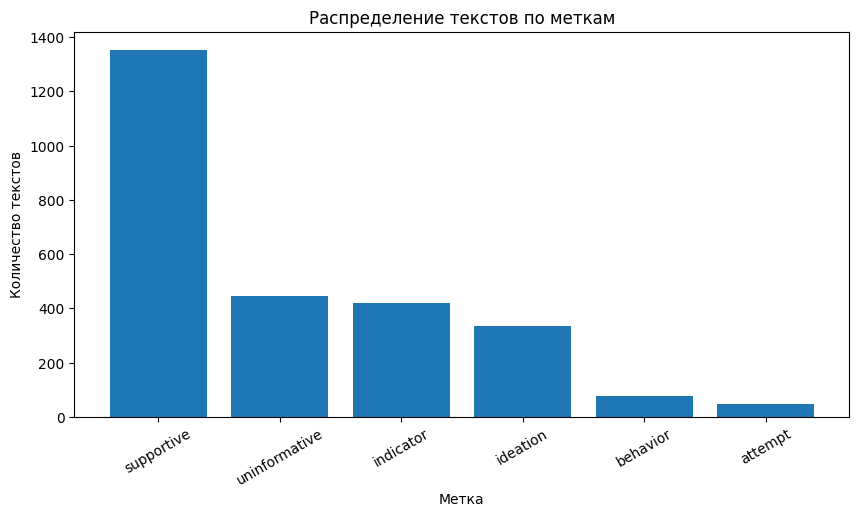

In [17]:

import matplotlib.pyplot as plt


counts = df["label"].value_counts()

percent = df["label"].value_counts(normalize=True) * 100

table = pd.DataFrame({
    "Количество": counts,
    "Процент (%)": percent.round(2)
})

display(table)

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values)

plt.title("Распределение текстов по меткам")
plt.xlabel("Метка")
plt.ylabel("Количество текстов")

plt.xticks(rotation=30)
plt.show()




В датасете наблюдается выраженный дисбаланс классов. Среди 2680 размеченных публикаций преобладает категория supportive. Наименьшее количество записей относится к категориям behavior и attempt. Это необходимо учитывать при дальнейшем обучении и оценке модели, поскольку она может хуже распознавать малочисленные классы.

## 1.3 Анализ исходных файлов
Датасет собран из 5 Excel-файлов. Нужно выяснить, одинаково ли распределены метки в каждом из них.


In [18]:
file_counts = df["source_file"].value_counts()

display(file_counts)


,count
source_file,
Redditors_and_posts_batch_IV_anonymized.xlsx,978
Redditors_and_posts_batch_II_anonymized.xlsx,934
Redditors_and_posts_batch_III_anonymized.xlsx,836
Redditors_and_posts_batch_V_anonymized.xlsx,755
Redditors_and_posts_batch_I_anonymized.xlsx,754


Все текста между файлами распределены относительно равномерно.

In [19]:
df_labeled = df[df["annotation_status"] == "labeled"]

file_labels = pd.crosstab(
    df_labeled["source_file"],
    df_labeled["label"]
)

display(file_labels)


label,attempt,behavior,ideation,indicator,supportive,uninformative
source_file,,,,,,
Redditors_and_posts_batch_III_anonymized.xlsx,6,7,27,23,15,0
Redditors_and_posts_batch_II_anonymized.xlsx,10,33,115,177,325,263
Redditors_and_posts_batch_IV_anonymized.xlsx,4,8,26,20,125,3
Redditors_and_posts_batch_I_anonymized.xlsx,15,11,104,38,532,49
Redditors_and_posts_batch_V_anonymized.xlsx,14,18,65,162,355,130


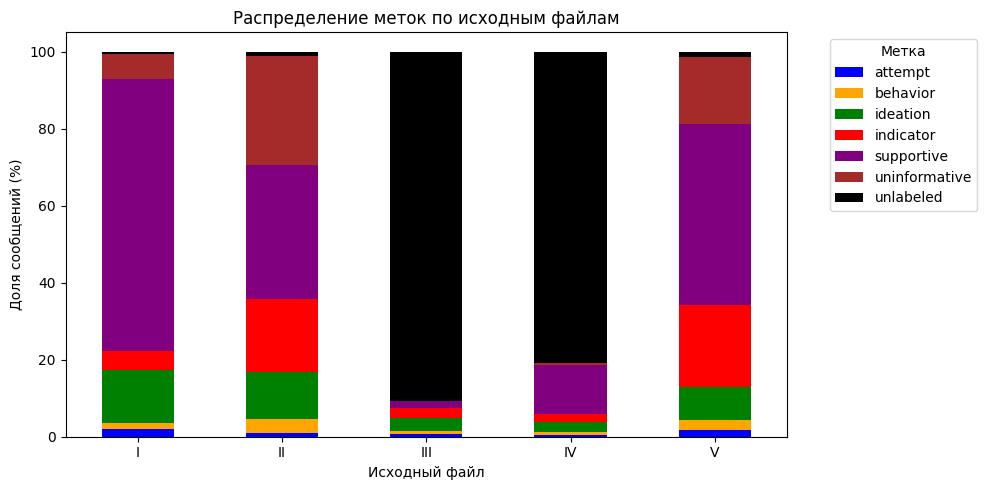

In [20]:
file_percent = pd.crosstab(
    df["source_file"],
    df["label"].fillna("unlabeled"),
    normalize="index"
) * 100


file_percent = file_percent.loc[[
    "Redditors_and_posts_batch_I_anonymized.xlsx",
    "Redditors_and_posts_batch_II_anonymized.xlsx",
    "Redditors_and_posts_batch_III_anonymized.xlsx",
    "Redditors_and_posts_batch_IV_anonymized.xlsx",
    "Redditors_and_posts_batch_V_anonymized.xlsx"
]]


file_percent.index = ["I", "II", "III", "IV", "V"]

colors = {
    "attempt": "blue",
    "behavior": "orange",
    "ideation": "green",
    "indicator": "red",
    "supportive": "purple",
    "uninformative": "brown",
    "unlabeled": "black"
}

file_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=[colors[label] for label in file_percent.columns]
)

plt.title("Распределение меток по исходным файлам")
plt.xlabel("Исходный файл")
plt.ylabel("Доля сообщений (%)")
plt.xticks(rotation=0)
plt.legend(title="Метка", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()




Полученные результаты указывают на неоднородность исходных данных и возможный эффект исходного файла . При дальнейшем обучении модели необходимо учитывать эти различия, чтобы избежать смещения результатов и некорректной оценки качества классификации.

Оставим только размеченные тексты

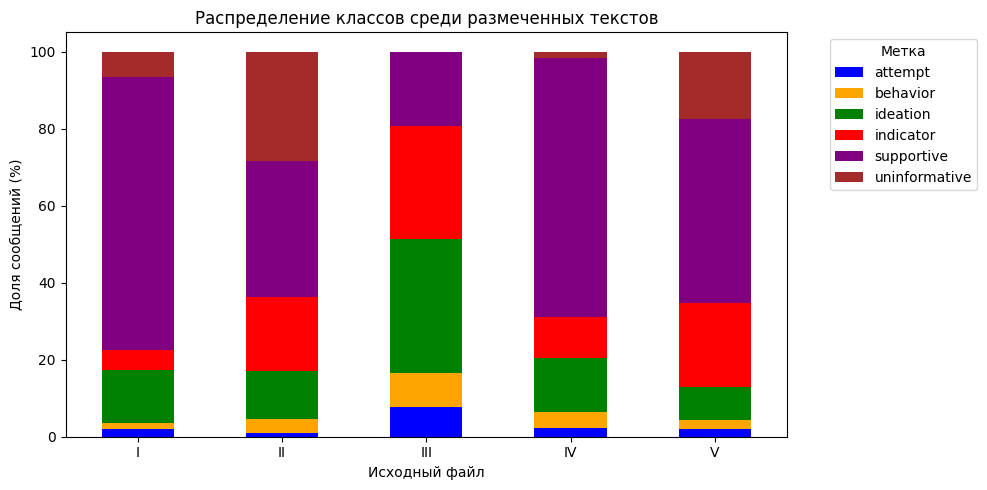

In [21]:
df_labeled = df[df["annotation_status"] == "labeled"]

file_percent = pd.crosstab(
    df_labeled["source_file"],
    df_labeled["label"],
    normalize="index"
) * 100

file_percent = file_percent.loc[[
    "Redditors_and_posts_batch_I_anonymized.xlsx",
    "Redditors_and_posts_batch_II_anonymized.xlsx",
    "Redditors_and_posts_batch_III_anonymized.xlsx",
    "Redditors_and_posts_batch_IV_anonymized.xlsx",
    "Redditors_and_posts_batch_V_anonymized.xlsx"
]]

file_percent.index = ["I", "II", "III", "IV", "V"]

colors = ["blue", "orange", "green", "red", "purple", "brown"]

file_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=colors
)

plt.title("Распределение классов среди размеченных текстов")
plt.xlabel("Исходный файл")
plt.ylabel("Доля сообщений (%)")
plt.xticks(rotation=0)
plt.legend(title="Метка", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


В файлах I и IV преобладает категория supportive, тогда как в файле III наиболее распространены классы ideation и indicator.

Файлы II и V имеют более разнообразное распределение категорий, включая uninformative.

## 1.4 Длина текстов

In [22]:
df["char_count"] = df["text"].str.len()

df["word_count"] = df["text"].str.split().str.len()

display(df[["text", "char_count", "word_count"]].head(10))


,text,char_count,word_count
0,Thank you very much for the picture. I printed...,148,30
1,My girlfriend of 7 years recently broke up wit...,2366,443
2,'I know how you feel man. My ex and I were tog...,725,149
3,'Try 7 years and a kid bub. It sucks when thin...,363,67
4,'now youre putting the pussy on a pedestal hah...,86,16
5,'Thats good to know. Im only familiar with vic...,106,21
6,'I think one of the hardest things about this ...,558,108
7,'Dont use that book as your basis of your unde...,276,55
8,'Thank you. I actually am not on any medicati...,481,87
9,'My girlfriend of 7 years recently broke up wi...,2466,459


Количество символов (char_count) помогает оценить технический объём текста. Это может пригодиться при его обработке и хранении.

Количество слов (word_count) помогает оценить содержательный объём сообщения. Это может быть полезным для анализа текстов и подготовки данных для моделей машинного обучения.

In [23]:
display(df[["char_count", "word_count"]].describe().round(2))

,char_count,word_count
count,4257.00,4257.00
mean,455.87,85.39
std,623.73,114.79
min,2.00,1.00
25%,110.00,21.00
50%,260.00,50.00
75%,549.00,103.00
max,8048.00,1510.00


Средняя длина составляет 456 символа (85 слов), медианная 260 символов (50 слов). Различие между средним и медианой указывает на правостороннюю асимметрию распределенияю Длина текстов варьируется от 2 до 8048 символов (от 1 до 1510 слов). При этом 75% сообщений содержат не более 103 слов. Полученные результаты важно учитывать при дальнейшей обработке текстов и выборе ограничений на длину входных данных модели.

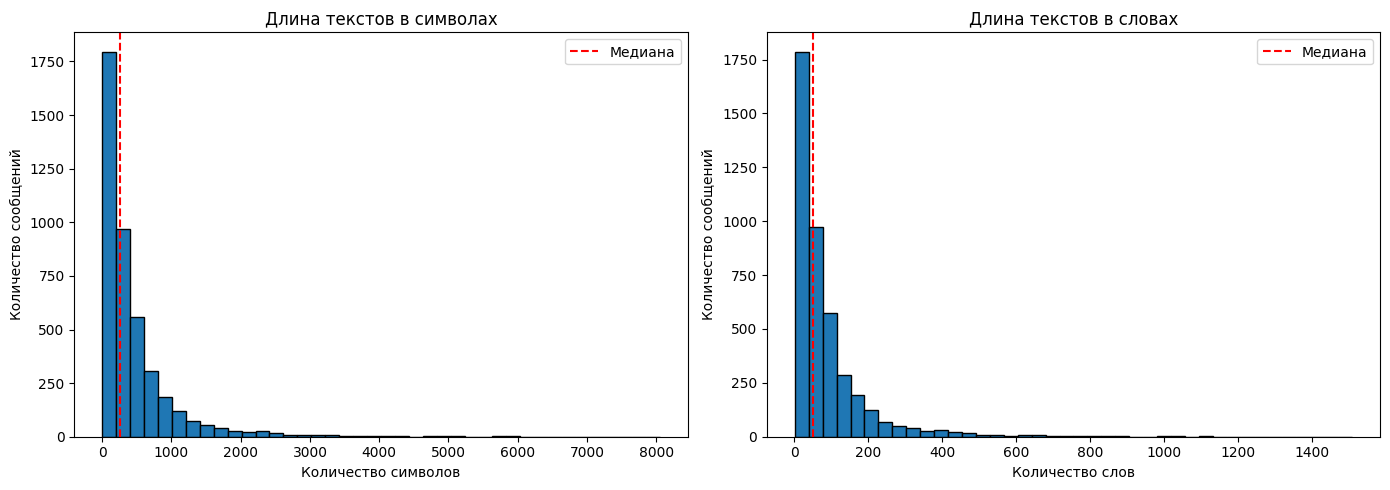

In [24]:

plt.figure(figsize=(14, 5))

# символы
plt.subplot(1, 2, 1)
plt.hist(df["char_count"], bins=40, edgecolor="black")
plt.axvline(df["char_count"].median(), color="red",
            linestyle="--", label="Медиана")
plt.title("Длина текстов в символах")
plt.xlabel("Количество символов")
plt.ylabel("Количество сообщений")
plt.legend()

# слова
plt.subplot(1, 2, 2)
plt.hist(df["word_count"], bins=40, edgecolor="black")
plt.axvline(df["word_count"].median(), color="red",
            linestyle="--", label="Медиана")
plt.title("Длина текстов в словах")
plt.xlabel("Количество слов")
plt.ylabel("Количество сообщений")
plt.legend()

plt.tight_layout()
plt.show()


Гистограммы длины текстов в символах и словах демонстрируют выраженную правостороннюю асимметрию распределения. Это свидетельствует о влиянии длинных сообщений на средние показатели. Оба способа измерения длины демонстрируют схожую картину распределения.

Сравним длина текста - категория (неразмеченные оставим)

In [25]:
df["label_group"] = df["label"].fillna("unlabeled")

length_stats = df.groupby("label_group")["word_count"].agg(
    ["count", "mean", "median", "min", "max"]
)

length_stats.columns = [
    "Количество", "Среднее", "Медиана", "Минимум", "Максимум"
]

display(length_stats.round(2))


,Количество,Среднее,Медиана,Минимум,Максимум
label_group,,,,,
attempt,49,170.76,86.0,6,955
behavior,77,109.90,76.0,5,653
ideation,337,128.73,91.0,5,1028
indicator,420,100.41,69.0,2,827
supportive,1352,81.19,49.5,1,1023
uninformative,445,31.33,18.0,1,1000
unlabeled,1577,87.14,48.0,1,1510


<Figure size 1100x600 with 0 Axes>

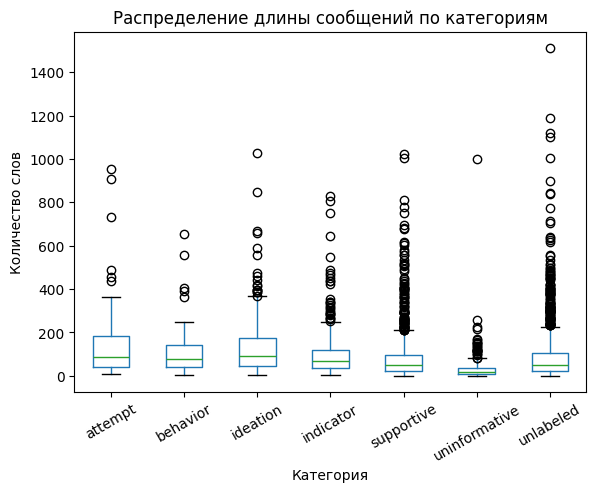

In [26]:
plt.figure(figsize=(11, 6))

df.boxplot(
    column="word_count",
    by="label_group",
    grid=False
)

plt.title("Распределение длины сообщений по категориям")
plt.suptitle("")
plt.xlabel("Категория")
plt.ylabel("Количество слов")
plt.xticks(rotation=30)
plt.show()


Анализ длины сообщений по категориям показал различия в объёме текстов. Наибольшая медианная длина наблюдается у категории ideation (91 слово). Наиболее короткие сообщения характерны для категории uninformative, медиана которой составляет всего 18 слов. Неразмеченные сообщения имеют медианную длину 48 слов.

Во всех категориях наблюдаются длинные сообщения, выходящие за пределы основного распределения. Различия между средними и медианными значениями указывают на правостороннюю асимметрию.

Длина текста может быть полезным дополнительным признаком при анализе категорий, однако сама по себе не позволяет определить уровень суицидального риска.

Построим второй boxplot, скрыв точки выбросов

<Figure size 1100x600 with 0 Axes>

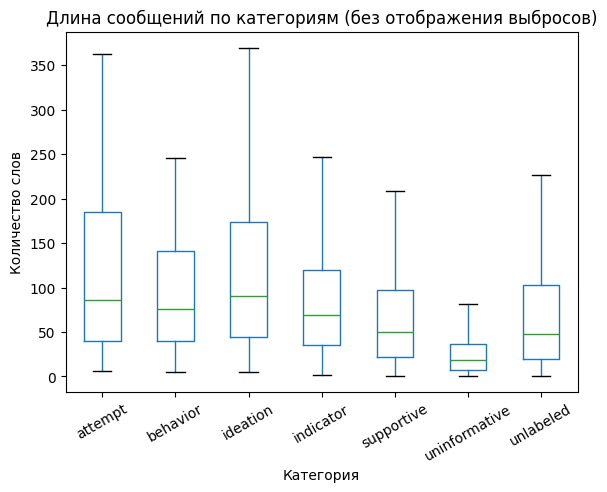

In [27]:

plt.figure(figsize=(11, 6))

df.boxplot(
    column="word_count",
    by="label_group",
    grid=False,
    showfliers=False
)

plt.title("Длина сообщений по категориям (без отображения выбросов)")
plt.suptitle("")
plt.xlabel("Категория")
plt.ylabel("Количество слов")
plt.xticks(rotation=30)
plt.show()


Анализ показал, что длина сообщений различается в зависимости от категории. Публикации, связанные с суицидальными мыслями ideation, попытками attempt и поведением behavior, в среднем и по медиане длиннее поддерживающих supportive и неинформативных uninformative сообщений. Это может быть связано с тем, что пользователи в таких публикациях подробнее описывают свои переживания, обстоятельства и личный опыт.

Наиболее короткие сообщения относятся к категории uninformative, что согласуется с недостатком содержательной информации в таких текстах.

Делаем вывод что длина сообщения потенциально может выступать дополнительным признаком при классификации текстов. НО категории значительно пересекаются по длине, поэтому определять суицидальный риск только по количеству слов нельзя.

Для этого в любом случае необходимо анализировать смысловое содержание публикаций.

## 1.5 Смысловой анализ

In [28]:
sample_texts = df.groupby("label_group").sample(
    n=2,
    random_state=42
)

for label, group in sample_texts.groupby("label_group"):
    print(f"\nКАТЕГОРИЯ: {label}")
    print("=" * 60)

    for text in group["text"]:
        print("\n", text)
        print("-" * 60)


КАТЕГОРИЯ: attempt

 'I guess I should try and ask more questions directly so here goes when did you guys find out you had Depression Anxiety (whatever else we might have) for me I remember being in 3rd grade I realized I was different from everyone else I always held back because of Fear and I prefered to be alone even at an early age didnt have many friends simply because once I left school I just wanted to be alone and its always stuck with me Depression appeared when I was 13-14 attempted suicide over a girl from then on was against suicide over a loved one but soon came to realize no one is exempt from the Pain use to think suicide was a cowards way out because of how society has brainwashed us saying its the easy way out have you attempted suicide before? even in a tunnel of despair suicide is pretty fucking difficult to get yourself to do its a war between our minds and our instincts, but my instincts have been wrong before panic attacks over talking to people???? thats suppose

Заметим, что некоторые сообщения могут не соответствовать своим меткам. Тогда создадим выборку для ручной проверки.

В ходе смыслового анализа было обнаружено сообщение №3710, отнесённое к категории attempt, хотя его содержание представляет собой предложение эмоциональной поддержки.

In [29]:

display(df.loc[[3710], [
    "user_id",
    "post_index",
    "original_label",
    "label",
    "annotation_status",
    "source_file",
    "text"
]])


,user_id,post_index,original_label,label,annotation_status,source_file,text
3710,user-181,0,attempt,attempt,labeled,Redditors_and_posts_batch_IV_anonymized.xlsx,"I think wed like to help you, but we might nee..."


Для дальнейшего исследования рассмотрим другие публикации этого пользователя, чтобы оценить возможное влияние контекста на назначение метки.

In [30]:

user_posts = df[df["user_id"] == "user-181"]

print("Количество сообщений:", len(user_posts))
print()
print(user_posts["label"].value_counts(dropna=False))

display(user_posts[[
    "post_index", "original_label", "text"
]])


Количество сообщений: 29

label
NaN        28
attempt     1
Name: count, dtype: int64


,post_index,original_label,text
3710,0,attempt,"I think wed like to help you, but we might nee..."
3711,1,NaN,'Im doing a lot. Im taking some really stimula...
3712,2,NaN,"'Well, lets talk about a few things that are g..."
3713,3,NaN,"'I am here to talk, not judge you. If I overst..."
3714,4,NaN,'There are no people who care about me. Not re...
3715,5,NaN,'Food can be an addiction just as much as alco...
3716,6,NaN,'It sounds like there is nothing stable in you...
3717,7,NaN,"'This is the way its always been, and its only..."
3718,8,NaN,'I can relate. I transferred from a community ...
3719,9,NaN,'http://www.suicide.org/international-suicide-...



Для дополнительной проверки качества разметки была изучена история публикаций пользователя user-181, у которого ранее обнаружено потенциальное несоответствие между содержанием сообщения и меткой attempt.

Всего в датасете представлено 29 сообщений этого пользователя, из которых только одно имеет метку attempt, а остальные 28 не размечены.

Смысловой анализ показал, что единственное размеченное сообщение (индекс 3710) содержит предложение эмоциональной поддержки. При этом среди неразмеченных публикаций обнаружены сообщения с прямыми упоминаниями суицидальных мыслей (например, индексы 3711 и 3722), а также обсуждения психологических трудностей и попыток самоубийства других людей.

Выявлено неоднозначное соответствие между содержанием отдельных сообщений и их разметкой. Метки могли присваиваться с учётом истории пользователя либо что разметка отдельных публикаций является неполной.



В связи с выявленными неоднозначностями было принято решение провести дополнительную автоматизированную смысловую разметку сообщений с помощью языковой модели (GPT 6.1 Sol).

ЛЛМ проверила структуру CSV: 4257 сообщений, из которых 2680 имели исходную метку, а 1577 оставались неразмеченными. Модель определяла категорию по смыслу каждого сообщения, различая личный опыт автора, обсуждение чужого опыта и поддержку собеседника. Дополнительно она проверила случайные выборки, случаи с попытками и подготовительными действиями и пересмотрела неоднозначные решения. Результаты были записаны в новый столбец new_label с сохранением исходных столбцов и порядка строк, а 1577 исходно неразмеченных сообщений остались без новой метки. После сохранения модель проверила количество строк, допустимость категорий и совпадение исходных полей с оригиналом. Расхождения рассматривались как основание для дополнительной проверки, а не как доказанные ошибки исходной разметки.

In [31]:
# Загружаем новый датасет
try:
    df_new = pd.read_csv("Reddit_C_SSRS_relabeled.csv")
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df_new = pd.read_csv(next(iter(uploaded)))

# Проверяем данные
print("Размер таблицы:", df_new.shape)
print("Пользователей:", df_new["user_id"].nunique())
print("Столбцы:", df_new.columns.tolist())

display(df_new.head(10))


Saving reddit_relabeled.csv to reddit_relabeled.csv
Размер таблицы: (4257, 8)
Пользователей: 376
Столбцы: ['user_id', 'post_index', 'text', 'original_label', 'label', 'annotation_status', 'source_file', 'new_label']


,user_id,post_index,text,original_label,label,annotation_status,source_file,new_label
0,user-655,0,Thank you very much for the picture. I printed...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,uninformative
1,user-655,1,My girlfriend of 7 years recently broke up wit...,ideation,ideation,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,ideation
2,user-655,2,'I know how you feel man. My ex and I were tog...,indicator,indicator,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,supportive
3,user-655,3,'Try 7 years and a kid bub. It sucks when thin...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,supportive
4,user-655,4,'now youre putting the pussy on a pedestal hah...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,uninformative
5,user-655,5,'Thats good to know. Im only familiar with vic...,indicator,indicator,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,uninformative
6,user-655,6,'I think one of the hardest things about this ...,indicator,indicator,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,indicator
7,user-655,7,'Dont use that book as your basis of your unde...,supportive,supportive,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,supportive
8,user-655,8,'Thank you. I actually am not on any medicati...,ideation,ideation,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,indicator
9,user-655,9,'My girlfriend of 7 years recently broke up wi...,ideation,ideation,labeled,Redditors_and_posts_batch_I_anonymized.xlsx,ideation


In [32]:

print("Всего сообщений:", len(df_new))

print("Исходных меток:",
      df_new["label"].notna().sum())

print("Новых меток:",
      df_new["new_label"].notna().sum())

print("Пустых новых меток:",
      df_new["new_label"].isna().sum())


Всего сообщений: 4257
Исходных меток: 2680
Новых меток: 2680
Пустых новых меток: 1577


После независимой смысловой переразметки сообщений проведём сравнение исходных категорий (label) с новыми (new_label).

Целью анализа является определение количества и доли совпадений и расхождений, а также выявление, какие категории чаще всего изменялись при повторной разметке.

In [33]:

df_compare = df_new[
    df_new["label"].notna() & df_new["new_label"].notna()
]

# Считаем совпадения и расхождения
same = (df_compare["label"] == df_compare["new_label"]).sum()
changed = (df_compare["label"] != df_compare["new_label"]).sum()

total = len(df_compare)

# Создаём таблицу
result = pd.DataFrame({
    "Количество": [same, changed],
    "Процент (%)": [
        round(same / total * 100, 2),
        round(changed / total * 100, 2)
    ]
}, index=["Совпали", "Изменились"])

display(result)


,Количество,Процент (%)
Совпали,1741,64.96
Изменились,939,35.04


Построим тепловую карту переходов, где на диагонали кол-ва сообщений, метки которых совпали

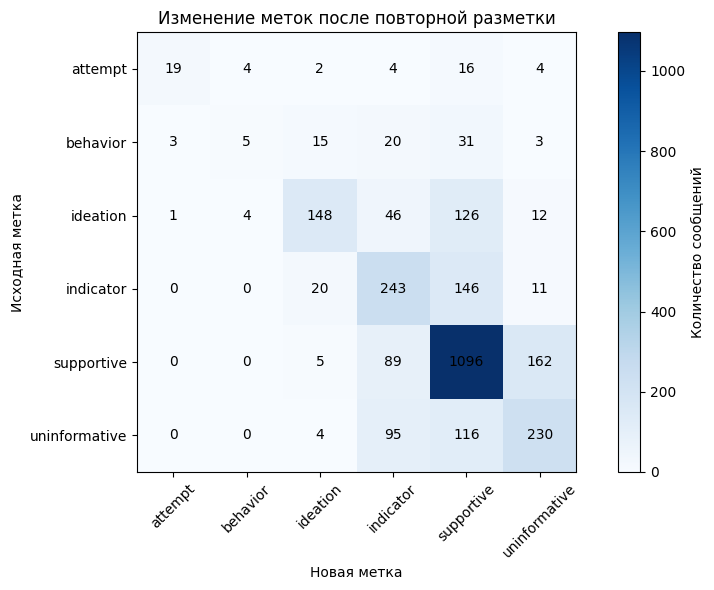

In [36]:

# Создаём таблицу переходов
changes = pd.crosstab(
    df_compare["label"],
    df_compare["new_label"]
)

# Строим тепловую карту
plt.figure(figsize=(9, 6))

plt.imshow(changes, cmap="Blues")
plt.colorbar(label="Количество сообщений")

plt.xticks(range(len(changes.columns)), changes.columns, rotation=45)
plt.yticks(range(len(changes.index)), changes.index)

# Подписываем числа внутри клеток
for i in range(len(changes.index)):
    for j in range(len(changes.columns)):
        plt.text(j, i, changes.iloc[i, j],
                 ha="center", va="center")

plt.title("Изменение меток после повторной разметки")
plt.xlabel("Новая метка")
plt.ylabel("Исходная метка")

plt.tight_layout()
plt.show()



Сравнение исходной и независимой LLM-разметки выявило значительные расхождения между категориями. Из 2680 размеченных сообщений совпадение наблюдается в 1741 случае (64,96%), тогда как для 939 сообщений (35,04%) была предложена другая метка.

Наибольшая доля изменений обнаружена в категориях behavior (93,5%), attempt (61,2%) и ideation (56,1%). Значительная часть сообщений из категорий суицидального риска была повторно классифицирована как supportive.

Полученные результаты указывают на существенную несогласованность двух вариантов разметки. Это может быть связано как с неоднозначностью исходных категорий, так и с ошибками или особенностями интерпретации языковой модели. Поэтому 35,04% следует рассматривать как долю расхождений, а не как подтверждённый процент ошибок исходной разметки.

In [38]:
# Оставляем сообщения, где метки отличаются
changed_texts = df_new[
    df_new["label"].notna() &
    df_new["new_label"].notna() &
    (df_new["label"] != df_new["new_label"])
]

# Выбираем 100 случайных сообщений
sample_changed = changed_texts.sample(
    n=100,
    random_state=10
)

# Показываем полный текст
for index, row in sample_changed.iterrows():
    print("Индекс:", index)
    print("Старая метка:", row["label"])
    print("Новая метка:", row["new_label"])
    print()
    print("Текст:", row["text"])
    print("=" * 70)


Индекс: 2548
Старая метка: ideation
Новая метка: supportive

Текст: 'Im on Prozac (generally, my doctor let my supply run out, and Im falling back) but it can work. My good baseline is 30 mg; at 40, I become badly suicidal interestingly enough. Give it a bit more time, and if it continues to not work, contact your doctor to see about what else can be done.And yes, it works wonders for my Anxiety Mental Depression as well.
Индекс: 1040
Старая метка: indicator
Новая метка: supportive

Текст: 'I have met a lot of people in a lot of horrible situations and Ive never seen a single one of them not be able to actually get out of it with a little bit of effort.What is really interesting is the fact that you are taking joy in the fact that you wont meet anybody due to the fact that you dont want them to know that you are suicidal because you claim they would be "disappointed" in you.  Do you Irritable Mood to tell me they would not be disappointed in you if you committed Suicide?  The first ste

Вручную разметим все 100 сообщений чтобы оценить разметку ЛЛМ.

Для дополнительной проверки качества разметки было рассмотрено 100 сообщений, у которых исходные метки не совпадали с метками, предложенными LLM. Проводилось сравнение категорий с содержанием текстов, чтобы оценить, насколько правильно модель определила смысл каждого сообщения.

В большинстве случаев новая разметка оказалась более подходящей. Например, некоторые сообщения изначально относились к категории indicator, хотя по содержанию авторы просто поддерживали других людей, давали советы или рекомендовали обратиться за помощью. В таких случаях категория supportive выглядела более логичной. Также модель достаточно хорошо справлялась с короткими сообщениями, которые не содержали информации о психологическом состоянии человека.

Однако были выявлены и спорные решения LLM. Например, в сообщениях №46 и №803 модель поставила supportive, хотя авторы рассказывали в том числе о собственных мыслях, связанных с самоповреждением или самоубийством. В сообщении №3262 автор описывал реальные действия по самоповреждению, поэтому исходная категория behavior оказалась более подходящей, чем предложенная моделью ideation. Встречались и обратные случаи, когда LLM находила признаки психологического неблагополучия в обычных сообщениях. Например, в №229 человек просто спрашивал, как не потерять друзей на работе, а в №2941 извинялся за неудачный вопрос. Информации в этих текстах недостаточно, чтобы относить их к indicator.

При проверке также было замечено, что некоторые сообщения сложно отнести только к одной категории. Например, в №912, №803 и №3377 авторы одновременно рассказывали о собственных психологических проблемах и старались поддержать других людей. Поэтому в таких случаях и исходная, и новая метка могли быть правильными. Таким образом, проблема не всегда заключается в ошибке разметки. Иногда сам текст содержит признаки сразу нескольких категорий, а модель должна выбрать только одну.

Кроме того, встречались сообщения, для которых было недостаточно контекста. Например, в №1436 человек просто писал, что находится в такой же ситуации, как собеседник. Без предыдущих сообщений непонятно, что именно он имеет в виду. Это также затрудняет классификацию.

По результатам проверки было установлено, что LLM помогает находить возможные ошибки в исходной разметке, однако полностью полагаться на её результаты нельзя. Особенно сложно модели различать supportive, indicator и ideation, когда человек одновременно говорит о собственных переживаниях и поддерживает другого. Поэтому автоматическая замена всех исходных меток новыми не рекомендуется. Более подходящим решением является сохранение обоих вариантов разметки с последующей проверкой спорных случаев.

Также важно учитывать, что для анализа были специально выбраны сообщения, в которых две разметки различались. Поэтому на основании этой выборки нельзя определить точный процент ошибок во всём датасете. Тем не менее проведённая проверка позволила выявить основные проблемы разметки и определить, на какие случаи следует обратить особое внимание перед обучением модели.

# Итоговые выводы

В ходе EDA был проведён анализ датасета, содержащего 4257 сообщений Reddit, из которых 2680 имели исходную разметку, а 1577 оставались неразмеченными. Были изучены структура данных, пропущенные значения, дубликаты, распределение категорий и длина сообщений.

Анализ показал, что категории распределены неравномерно. Наибольшее количество сообщений относится к категории supportive, тогда как категории attempt и behavior встречаются значительно реже. Длина текстов также существенно различается: от коротких сообщений из нескольких слов до подробных рассказов о личных переживаниях. Эти особенности необходимо учитывать при дальнейшем обучении модели.

Для оценки качества исходной разметки была проведена повторная классификация сообщений с помощью LLM. В результате для 939 из 2680 размеченных сообщений предложенные категории не совпали с исходными. Для более подробного анализа была дополнительно рассмотрена выборка из 100 сообщений с расхождениями.

Проверка показала, что LLM во многих случаях предлагает более подходящие категории, однако некоторые решения остаются спорными. Часть сообщений одновременно содержит признаки психологического неблагополучия и элементы поддержки других пользователей, что затрудняет выбор одной категории. Кроме того, встречаются короткие сообщения, смысл которых сложно определить без дополнительного контекста.

По результатам анализа было принято решение не заменять исходную разметку автоматически. Для дальнейшей работы целесообразно сохранить как исходные, так и предложенные LLM метки, а сообщения с расхождениями рассматривать как потенциально спорные.

Датасет может быть использован для дальнейших экспериментов по классификации текстов, однако необходимо учитывать дисбаланс категорий и возможные ошибки разметки. Следующим этапом является подготовка данных для машинного обучения, разделение на обучающую и тестовую выборки и выбор модели классификации.